<center>МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ </center>
<center>ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ </center>
<center>«НОВОСИБИРСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ»</center>
<center>Кафедра Вычислительной техники </center>
<br>
<center> <b> <font size="5">  ОТЧЁТ </font>  </b>  </center>   
<center><font size="3">по лабораторной работе №1</font></center>
<center><font size="3">по дисциплине: «Анализ и интепретация данных» </font></center>
<br>

Выполнили:
- Клименко К.В.
- Бадагов А.В.

Преподаватель: Альсова О.К.

<center>  Новосибирск, 2026  </center>

# Цель работ

- Получить навыки применения методов первичного разведочного
анализа данных и статистической проверки гипотез для решения задач анализа данных (АД);
- Изучить средства Python для проведения первичного разведочного анализа данных (методы визуализации, описательной статистики, статистической проверки гипотез) на примере решения конкретной задачи АД.
- Изучить средства Python для исследования взаимосвязей признаков (методы корреляционного, рангового корреляционного, дисперсионного анализа, анализа таблиц сопряженности на примере решения конкретной задачи АД.

# Ход работы

In [1]:
# Проверка версии и пути к выбранному интерпретатору
import sys
print(f"Версия Python - {sys.version}")
print(f"Путь к интерпретатору Python - {sys.executable}")

Версия Python - 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Путь к интерпретатору Python - /usr/bin/python3


In [2]:
# Python 3.13.15
import pandas as pd
import numpy  as np

import sklearn
from sklearn import linear_model
from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score

%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import cm
import seaborn as sns

Для загрузки табличных данных из файла применим функцию .read_csv() с указанием параметров: путь к файлу csv, разделитель для колонок - точка с запятой, в качестве десятичного разделителя - точка, а индекс заголовка 0.

In [3]:
df = pd.read_csv("./var_1.csv",
        sep=';',
        decimal='.',
        header=0
    )
df[0:]

,N,Group,Gender,Age,Experience,% of developments completed on time,Number of errors identified by the user,Customer satisfaction (score),Customer satisfaction (level),Quality of documentation
0,1,1,1,24,1.9,79,14,69,Medium,2
1,2,1,2,26,1.5,90,14,86,High,3
2,3,1,2,25,1.9,80,18,64,Low,4
3,4,1,2,30,1.5,89,17,81,High,2
4,5,1,1,27,2.6,91,22,67,Medium,2
...,...,...,...,...,...,...,...,...,...,...
195,196,2,1,36,6.7,94,12,95,High,3
196,197,2,2,33,4.8,88,21,67,Medium,2
197,198,2,1,33,5.4,93,24,68,Medium,1
198,199,2,2,35,6.0,84,17,74,Medium,4


##  Первичный анализ исходных данных

Далее мы вывели на экран список колонок, затем форму матрицы датафрейма, а также количество null значений для каждого столбца.
По итогам вывода, в нашем исходном датафрейме 10 признаков:
1. 'N'
2. 'Group'
3. 'Gender'
4. 'Age'
5. 'Experience'
6. '% of developments completed on time'
7. 'Number of errors identified by the user'
8. 'Customer satisfaction (score)'
9. 'Customer satisfaction (level)'
10. 'Quality of documentation'

и 200 записей.

In [4]:
print(list(df.columns), "\n")
print(df.shape, "\n")
print(df.isna().sum(), "\n")

['N', 'Group', 'Gender', 'Age', 'Experience', '% of developments completed on time', 'Number of errors identified by the user', 'Customer satisfaction (score)', 'Customer satisfaction (level)', 'Quality of documentation'] 

(200, 10) 

N                                          0
Group                                      0
Gender                                     0
Age                                        0
Experience                                 0
% of developments completed on time        0
Number of errors identified by the user    0
Customer satisfaction (score)              0
Customer satisfaction (level)              0
Quality of documentation                   0
dtype: int64 



Переименовали колонки в более короткие и понятные названия, сохраняя их смысл: Dev_Percent_on_Time (процент разработок, выполненных в срок), User_Errors (ошибки пользователя), Satisfaction_Score (числовая оценка удовлетворенности), Satisfaction_Level (уровень удовлетворенности), Doc_Quality (качество документации).

In [5]:
df = df.rename(columns={
    "% of developments completed on time": "Dev_Percent_on_Time",
    "Number of errors identified by the user": "User_Errors",
    "Customer satisfaction (score)": "Satisfaction_Score",
    "Customer satisfaction (level)": "Satisfaction_Level",
    "Quality of documentation": "Doc_Quality"
})
df

,N,Group,Gender,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score,Satisfaction_Level,Doc_Quality
0,1,1,1,24,1.9,79,14,69,Medium,2
1,2,1,2,26,1.5,90,14,86,High,3
2,3,1,2,25,1.9,80,18,64,Low,4
3,4,1,2,30,1.5,89,17,81,High,2
4,5,1,1,27,2.6,91,22,67,Medium,2
...,...,...,...,...,...,...,...,...,...,...
195,196,2,1,36,6.7,94,12,95,High,3
196,197,2,2,33,4.8,88,21,67,Medium,2
197,198,2,1,33,5.4,93,24,68,Medium,1
198,199,2,2,35,6.0,84,17,74,Medium,4


В датафрейме представлены показатели работы программистов крупной
организации: N — порядковый номер записи, не несущий смысловой нагрузки, поэтому удаляется через df.drop(); Group — группа испытуемых; Gender — пол (1-м, 2-ж); Age — возраст; Experience — опыт работы; Dev_Percent_on_Time — процент разработок, выполненных в срок; User_Errors — количество ошибок, выявленных пользователем; Satisfaction_Score — числовая оценка удовлетворённости клиента; Satisfaction_Level — категориальный уровень удовлетворённости; Doc_Quality — качество документации. Эти признаки используются для анализа влияния факторов на результаты деятельности и удовлетворённость заказчиков.

In [6]:
df = df.drop(
        labels=['N'],
        axis=1
    )
df

,Group,Gender,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score,Satisfaction_Level,Doc_Quality
0,1,1,24,1.9,79,14,69,Medium,2
1,1,2,26,1.5,90,14,86,High,3
2,1,2,25,1.9,80,18,64,Low,4
3,1,2,30,1.5,89,17,81,High,2
4,1,1,27,2.6,91,22,67,Medium,2
...,...,...,...,...,...,...,...,...,...
195,2,1,36,6.7,94,12,95,High,3
196,2,2,33,4.8,88,21,67,Medium,2
197,2,1,33,5.4,93,24,68,Medium,1
198,2,2,35,6.0,84,17,74,Medium,4


В датафрейме присутствовал единственный ординальный категориальный признак — Satisfaction_Level, имеющий естественный порядок уровней (например, Low < Medium < High). Остальные категориальные переменные (Group, Gender) являются номинальными и не обладают внутренней упорядоченностью.

In [7]:
satisfaction_level_order = ['Low', 'Medium', 'High']
df['Satisfaction_Level'] = df['Satisfaction_Level'].map({v: i + 1 for i, v in enumerate(satisfaction_level_order)})

print(df.dtypes)

Group                    int64
Gender                   int64
Age                      int64
Experience             float64
Dev_Percent_on_Time      int64
User_Errors              int64
Satisfaction_Score       int64
Satisfaction_Level       int64
Doc_Quality              int64
dtype: object


Функция get_characteristics формирует сводную таблицу описательных статистик для количественных признаков, исключая категориальные переменные (Group, Gender, Satisfaction_Level, Doc_Quality). Для каждого числового столбца рассчитываются 11 метрик: минимум, максимум, среднее, стандартное отклонение, дисперсия, квартили (25% и 75%), медиана, мода, асимметрия и эксцесс. Значения округляются до трёх знаков после запятой для удобства восприятия. Функция применяется к трём подвыборкам: отдельно для каждой группы по полу (Gender == 1 и Gender == 2) и ко всему датасету целиком, что позволяет провести сравнительный анализ распределений и выявить различия в характеристиках между группами респондентов.

In [8]:
def get_characteristics(df:pd.DataFrame) -> pd.DataFrame:
  max = ['max']
  min = ['min']
  mean=['mean']
  std=['std']
  var=['var']
  q25=['q25']
  q75=['q75']
  median=['median']
  mode=['mode']
  skew=['skew']
  kurt=['kurt']

  numeric_df = df.drop(
      columns=['Group', 'Gender', 'Satisfaction_Level', 'Doc_Quality']
  )
  for name in numeric_df.columns:
      max.append(df[name].max())
      min.append(df[name].min())
      mean.append(round(df[name].mean(), 3))
      std.append(round(df[name].std(), 3))
      var.append(round(df[name].var(), 3))
      q25.append(df[name].quantile(0.25))
      q75.append(df[name].quantile(0.75))
      median.append(round(df[name].median(), 3))
      mode.append(str(df[name].mode().values))
      skew.append(float(round(df[name].skew(), 3)))
      kurt.append(float(round(df[name].kurt(), 3)))

  result = np.array([max, min, mean, std, var, q25, q75, median, mode, skew, kurt])

  return pd.DataFrame(result, columns=['metrix'] + list(numeric_df))

group1 = get_characteristics(df[df['Gender'] == 1])
group2 = get_characteristics(df[df['Gender'] == 2])
all = get_characteristics(df)

In [9]:
group1

,metrix,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
0,max,37,8.8,100,29,99
1,min,22,1.1,73,1,55
2,mean,29.84,4.116,89.34,16.01,77.93
3,std,3.018,2.132,5.621,5.548,10.751
4,var,9.105,4.547,31.6,30.778,115.581
5,q25,27.0,2.0,85.75,12.0,69.0
6,q75,32.0,5.825,93.25,20.0,86.0
7,median,30.0,4.8,89.0,16.0,78.0
8,mode,[30],[2. 2.2],[92],[17],[69]
9,skew,-0.01,0.091,-0.322,-0.128,0.022


In [10]:
group2

,metrix,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
0,max,35,8.0,98,29,99
1,min,22,0.8,75,2,59
2,mean,29.18,3.706,88.63,15.76,78.7
3,std,2.855,2.077,5.033,5.282,9.729
4,var,8.149,4.316,25.326,27.901,94.657
5,q25,27.0,1.8,85.0,13.0,72.0
6,q75,31.0,5.8,92.0,19.0,87.0
7,median,29.0,2.7,88.0,16.0,79.0
8,mode,[28],[1.5],[87],[16],[89]
9,skew,0.027,0.33,-0.155,-0.072,-0.11


In [11]:
all

,metrix,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
0,max,37,8.8,100,29,99
1,min,22,0.8,73,1,55
2,mean,29.51,3.911,88.985,15.885,78.315
3,std,2.948,2.11,5.334,5.404,10.234
4,var,8.693,4.452,28.447,29.208,104.739
5,q25,27.0,1.9,85.0,12.0,70.0
6,q75,31.0,5.8,93.0,19.25,86.25
7,median,30.0,3.6,89.0,16.0,79.0
8,mode,[30],[2. 2.2],[88 92],[17],[69 84 89]
9,skew,0.025,0.209,-0.228,-0.098,-0.045


Для каждого признака из списка был построен горизонтальный boxplot, а также рассчитаны границы межквартильного размаха (IQR). Нижняя и верхняя границы выбросов определены по формуле как:

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

Фактические «усы» (whiskers) на графике соответствуют минимальному и максимальному значениям в пределах этих границ. Полученные границы сохранены в словаре thresholdDict и могут использоваться позже для фильтрации или обработки выбросов. Тип данных (целый/вещественный) учтён при сохранении значений.

Age: 27.0, 31.0, 22, 37
Experience: 1.9, 5.8, 0.8, 8.8
Dev_Percent_on_Time: 85.0, 93.0, 73, 100
User_Errors: 12.0, 19.25, 2, 29
Satisfaction_Score: 70.0, 86.25, 55, 99
Satisfaction_Level: 2.0, 3.0, 1, 3
Doc_Quality: 2.0, 3.0, 1, 4


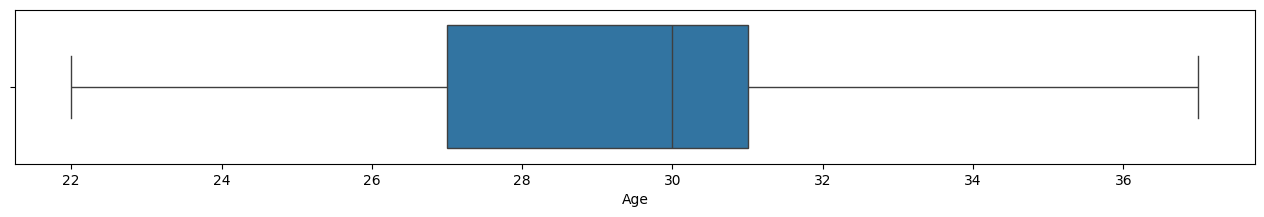

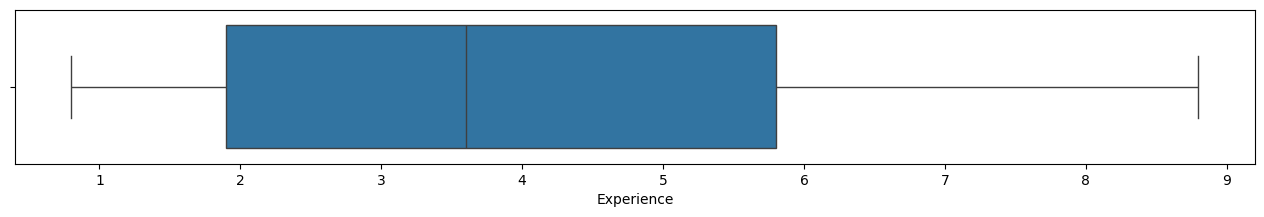

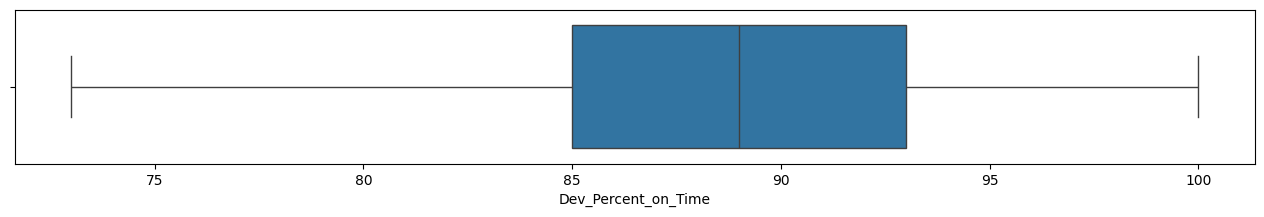

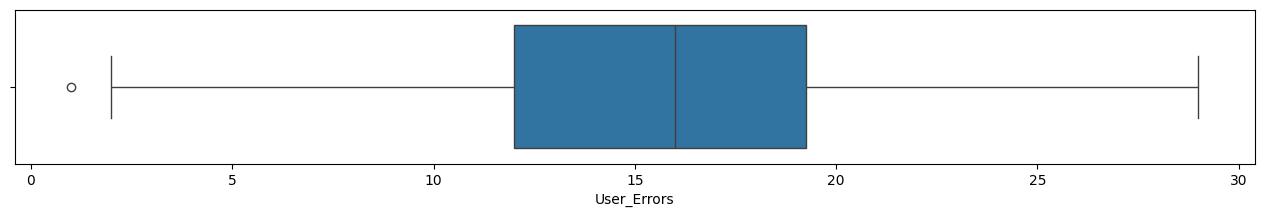

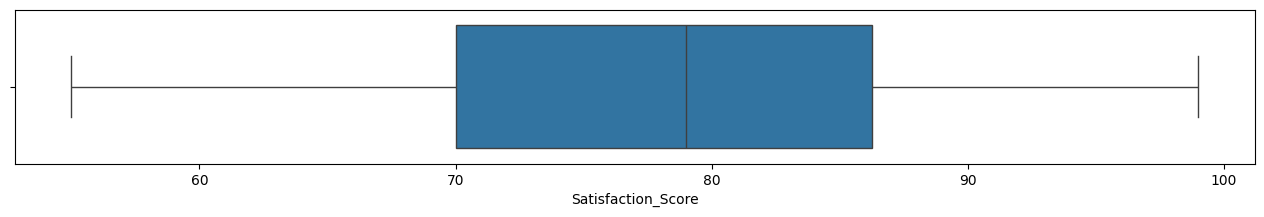

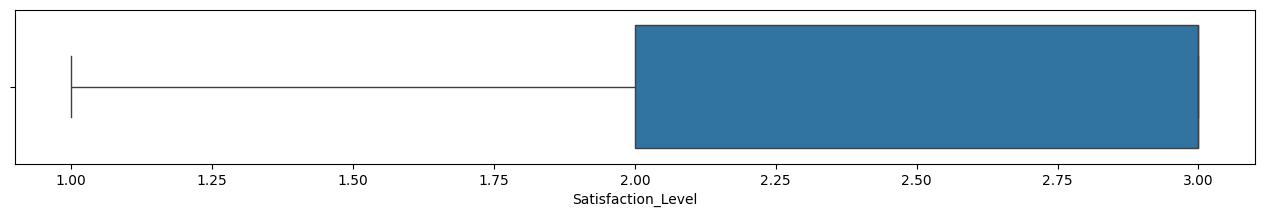

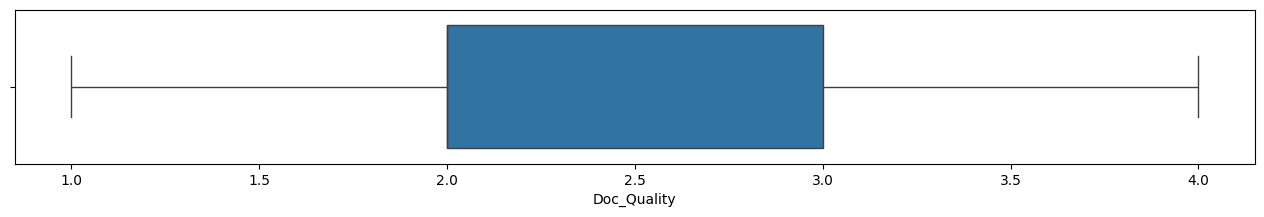

In [12]:
thresholdDict = {}
cols = [col for col in df.columns if col not in ['Group', 'Gender']]

for feature_name in (cols):
  data=df[feature_name]
  plt.figure(figsize=(16,2))
  # На созданном полотне отрисовать boxplot
  sns.boxplot(data=data, orient='h')

  q1 = np.percentile(data, 25)
  q3 = np.percentile(data, 75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  lower_whisker = data[data >= lower_bound].min()
  upper_whisker = data[data <= upper_bound].max()

  print(f"{feature_name}: {q1}, {q3}, {lower_whisker}, {upper_whisker}")

  is_int = pd.api.types.is_integer_dtype(df[feature_name].dtype)
  lw = int(lower_whisker) if is_int else float(lower_whisker)
  uw = int(upper_whisker) if is_int else float(upper_whisker)
  thresholdDict[feature_name] = (lw, uw)

Выведен словарь thresholdDict, содержащий рассчитанные границы (нижнюю и верхнюю) для каждого признака на основе метода межквартильного размаха (IQR).

In [13]:
print (thresholdDict)

{'Age': (22, 37), 'Experience': (0.8, 8.8), 'Dev_Percent_on_Time': (73, 100), 'User_Errors': (2, 29), 'Satisfaction_Score': (55, 99), 'Satisfaction_Level': (1, 3), 'Doc_Quality': (1, 4)}


Для каждого признака на основе сохранённых пороговых значений (thresholdDict) подсчитано количество наблюдений, выходящих за пределы диапазона. Приведена абсолютная численность выбросов, общее количество значений и доля выбросов в процентах. Это позволяет оценить, насколько сильно каждый признак «загрязнён» выбросами.

In [14]:
print(thresholdDict, '\n')
for feature_name  in thresholdDict:
    threshMin =  thresholdDict[feature_name][0] # извлечь нижнее пороговое
    threshMax =  thresholdDict[feature_name][1] # извлечь верхнее пороговое

    # Получить кол-во эл. вне пороговых значений. Прием - фильтрация
    over_count = len(df[~((df[feature_name] >= threshMin) & (df[feature_name] <= threshMax))])

    dcount = df[feature_name].count() # кол-во эл. общее

    print ('''{}. Принимаем пороговые значение равными {}. Кол-во эл. вне пороговых - {} из {} значение(ий) ({:.1%})\n'''.format(
        feature_name,
        thresholdDict[feature_name],
        over_count,
        dcount,
        over_count/ dcount,
    ))

{'Age': (22, 37), 'Experience': (0.8, 8.8), 'Dev_Percent_on_Time': (73, 100), 'User_Errors': (2, 29), 'Satisfaction_Score': (55, 99), 'Satisfaction_Level': (1, 3), 'Doc_Quality': (1, 4)} 

Age. Принимаем пороговые значение равными (22, 37). Кол-во эл. вне пороговых - 0 из 200 значение(ий) (0.0%)

Experience. Принимаем пороговые значение равными (0.8, 8.8). Кол-во эл. вне пороговых - 0 из 200 значение(ий) (0.0%)

Dev_Percent_on_Time. Принимаем пороговые значение равными (73, 100). Кол-во эл. вне пороговых - 0 из 200 значение(ий) (0.0%)

User_Errors. Принимаем пороговые значение равными (2, 29). Кол-во эл. вне пороговых - 1 из 200 значение(ий) (0.5%)

Satisfaction_Score. Принимаем пороговые значение равными (55, 99). Кол-во эл. вне пороговых - 0 из 200 значение(ий) (0.0%)

Satisfaction_Level. Принимаем пороговые значение равными (1, 3). Кол-во эл. вне пороговых - 0 из 200 значение(ий) (0.0%)

Doc_Quality. Принимаем пороговые значение равными (1, 4). Кол-во эл. вне пороговых - 0 из 200 зн

Построим гистограммы для каждого признака, что бы визуально определить частоту повтора значений признаков (идентифицировать тип распределения каждого признака),  что критически важно для выбора корректных статистических методов и алгоритмов машинного обучения.

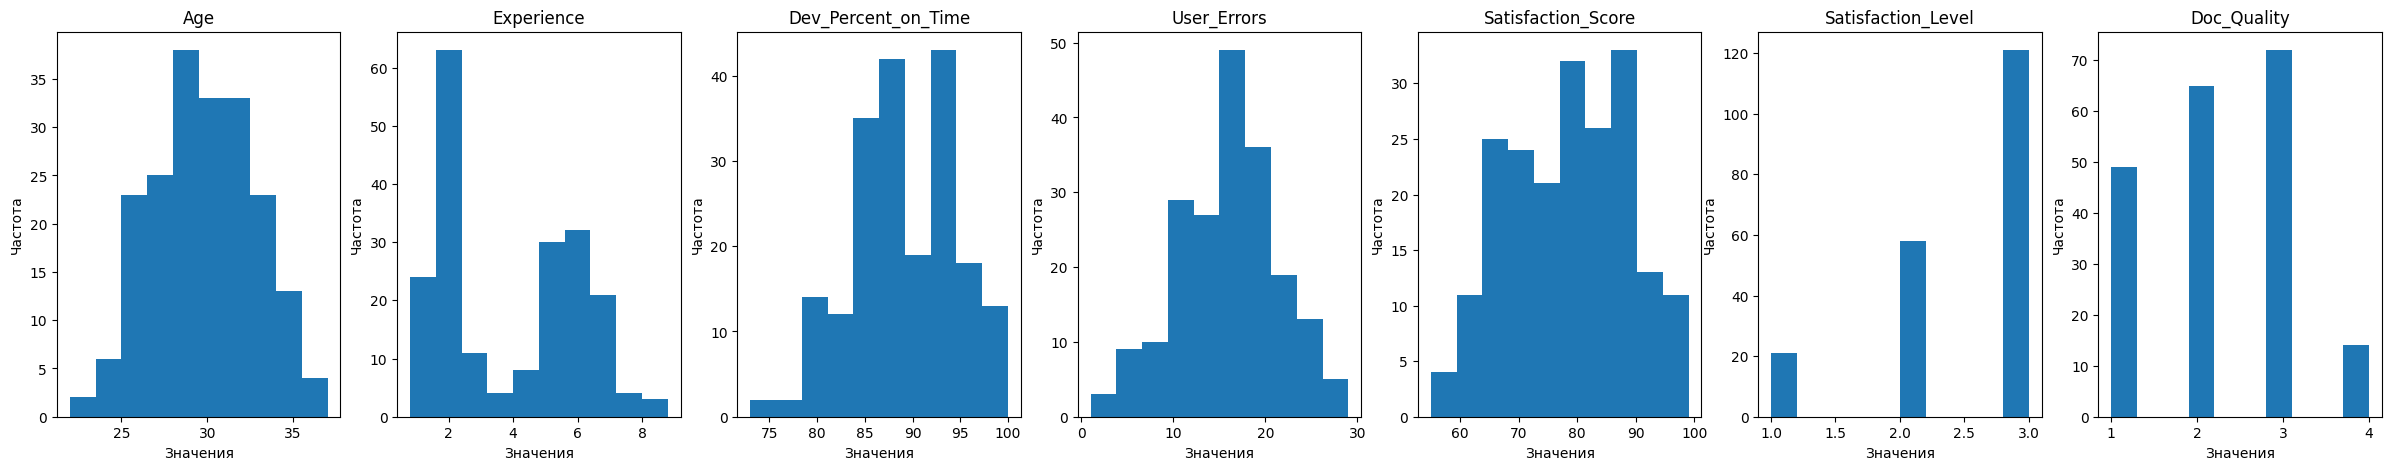

In [15]:
# Строим гистограммы по каждому признаку:

plt.figure(figsize=(30, 5))
plot_number = 0

for feature_name in (cols):
    plot_number += 1

    plt.subplot(1, len(cols), plot_number)

    plt.hist(df[feature_name]) # Построение гистрограммы

    plt.title(feature_name)
    plt.xlabel(u'Значения')
    plt.ylabel(u'Частота')

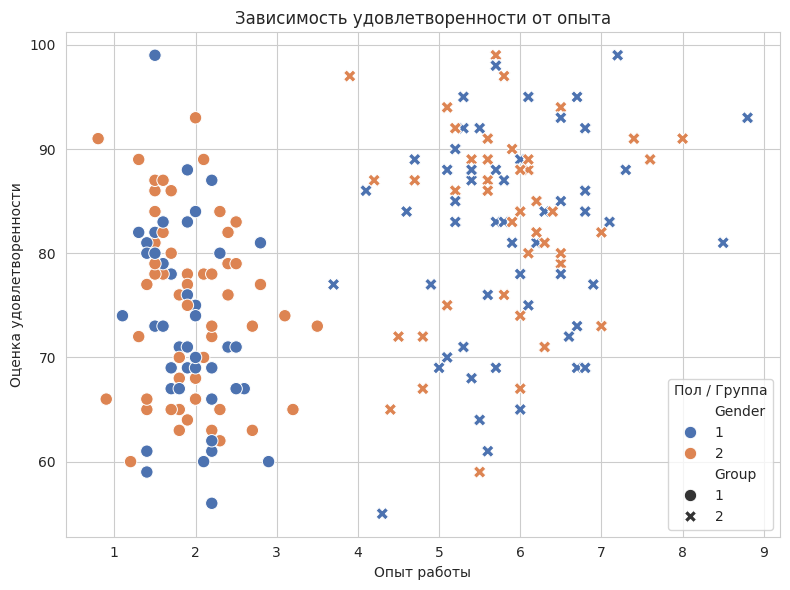

In [16]:
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

quant_cols = [
    'Age',
    'Experience',
    'Dev_Percent_on_Time',
    'User_Errors',
    'Satisfaction_Score',
    'Doc_Quality'
]

cat_cols = ['Group', 'Gender', 'Satisfaction_Level']

# 1. ДИАГРАММА РАССЕЯНИЯ

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Experience',
    y='Satisfaction_Score',
    hue='Gender',
    style='Group',
    palette='deep',
    s=80
)

plt.title('Зависимость удовлетворенности от опыта')
plt.xlabel('Опыт работы')
plt.ylabel('Оценка удовлетворенности')
plt.legend(title='Пол / Группа')
plt.tight_layout()
plt.show()

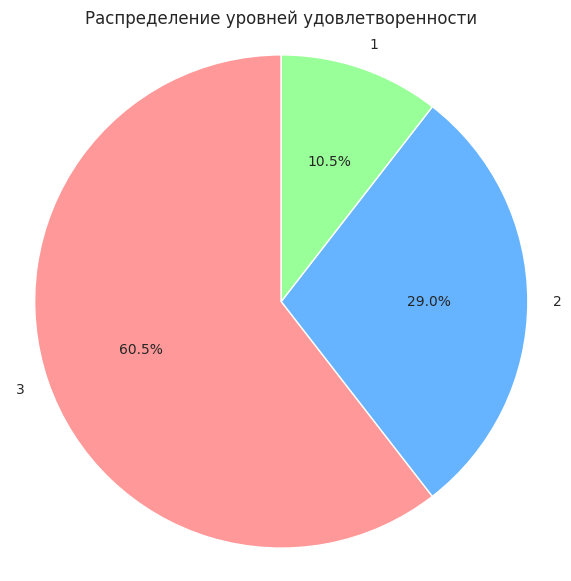

In [17]:
# 2. РАДИАЛЬНАЯ ДИАГРАММА ПО КАЧЕСТВЕННОМУ ПРИЗНАКУ

plt.figure(figsize=(7, 7))

satisfaction_counts = df['Satisfaction_Level'].value_counts()

plt.pie(
    satisfaction_counts,
    labels=satisfaction_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#ff9999', '#66b3ff', '#99ff99'],
    wedgeprops={'edgecolor': 'white'}
)

plt.title('Распределение уровней удовлетворенности')
plt.axis('equal')
plt.show()

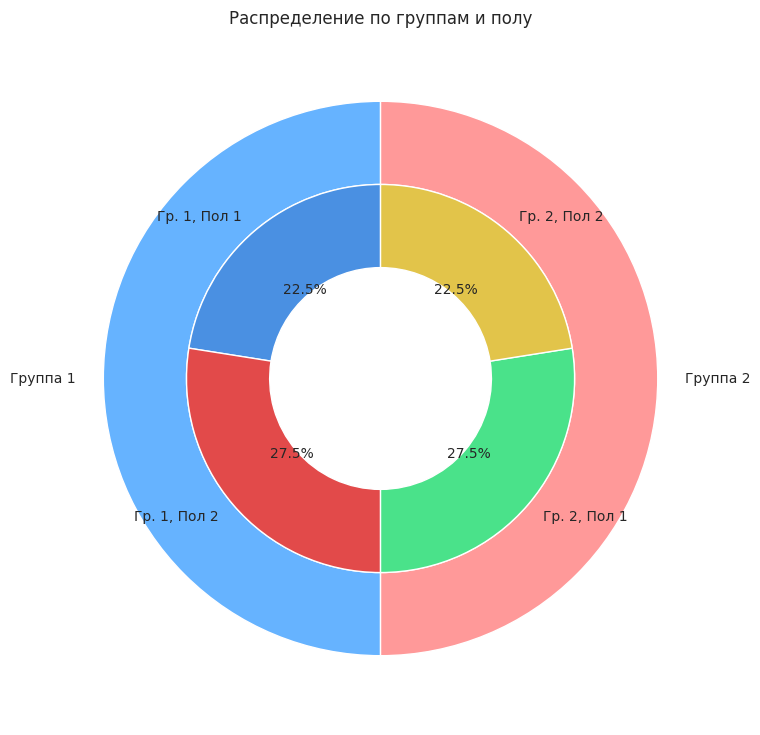

In [18]:
# 3. КАТЕГОРИАЛЬНАЯ РАДИАЛЬНАЯ ДИАГРАММА ПО ПОЛУ И ГРУППЕ

group_gender_counts = (
    df.groupby(['Group', 'Gender'])
    .size()
    .unstack(fill_value=0)
)

group_counts = df['Group'].value_counts().sort_index()

gender_counts = group_gender_counts.values.flatten()

fig, ax = plt.subplots(figsize=(9, 9))

group_colors = ['#66b3ff', '#ff9999']
gender_colors = [
    '#4a90e2', '#e24a4a',
    '#4ae28a', '#e2c44a'
]

ax.pie(
    group_counts,
    radius=1,
    labels=[f'Группа {g}' for g in group_counts.index],
    startangle=90,
    colors=group_colors,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

inner_labels = [
    f'Гр. {g}, Пол {gen}'
    for g in group_gender_counts.index
    for gen in group_gender_counts.columns
]

ax.pie(
    gender_counts,
    radius=0.7,
    labels=inner_labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=gender_colors,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

ax.set(
    aspect='equal',
    title='Распределение по группам и полу'
)

plt.show()

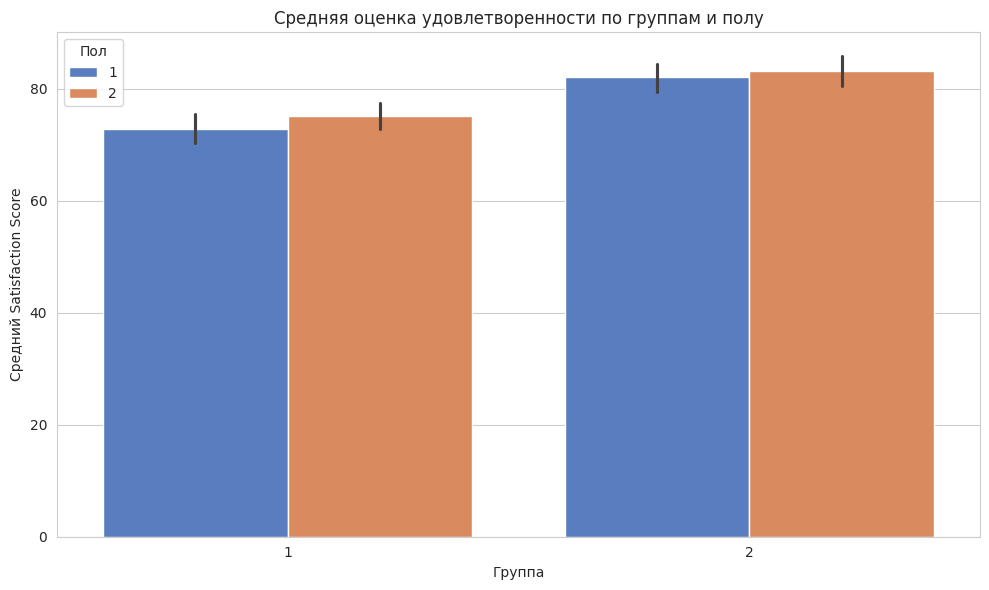

In [19]:
# 4. КАТЕГОРИАЛЬНАЯ СТОЛБИКОВАЯ ДИАГРАММА - КОЛИЧЕСТВЕННЫЙ ПРИЗНАК ПО ПОЛУ И ГРУППЕ

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='Group',
    y='Satisfaction_Score',
    hue='Gender',
    palette='muted',
    errorbar=('ci', 95)
)

plt.title('Средняя оценка удовлетворенности по группам и полу')
plt.xlabel('Группа')
plt.ylabel('Средний Satisfaction Score')
plt.legend(title='Пол')
plt.tight_layout()
plt.show()

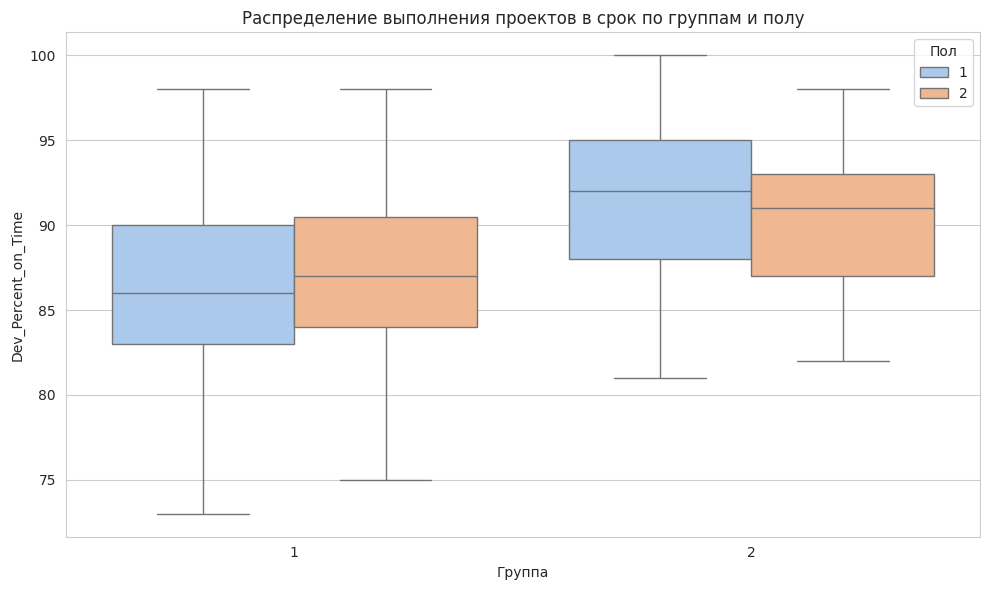

In [20]:
# 5. ДИАГРАММА РАЗМАХА (BOXPLOT)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Group',
    y='Dev_Percent_on_Time',
    hue='Gender',
    palette='pastel'
)

plt.title('Распределение выполнения проектов в срок по группам и полу')
plt.xlabel('Группа')
plt.ylabel('Dev_Percent_on_Time')
plt.legend(title='Пол')
plt.tight_layout()
plt.show()

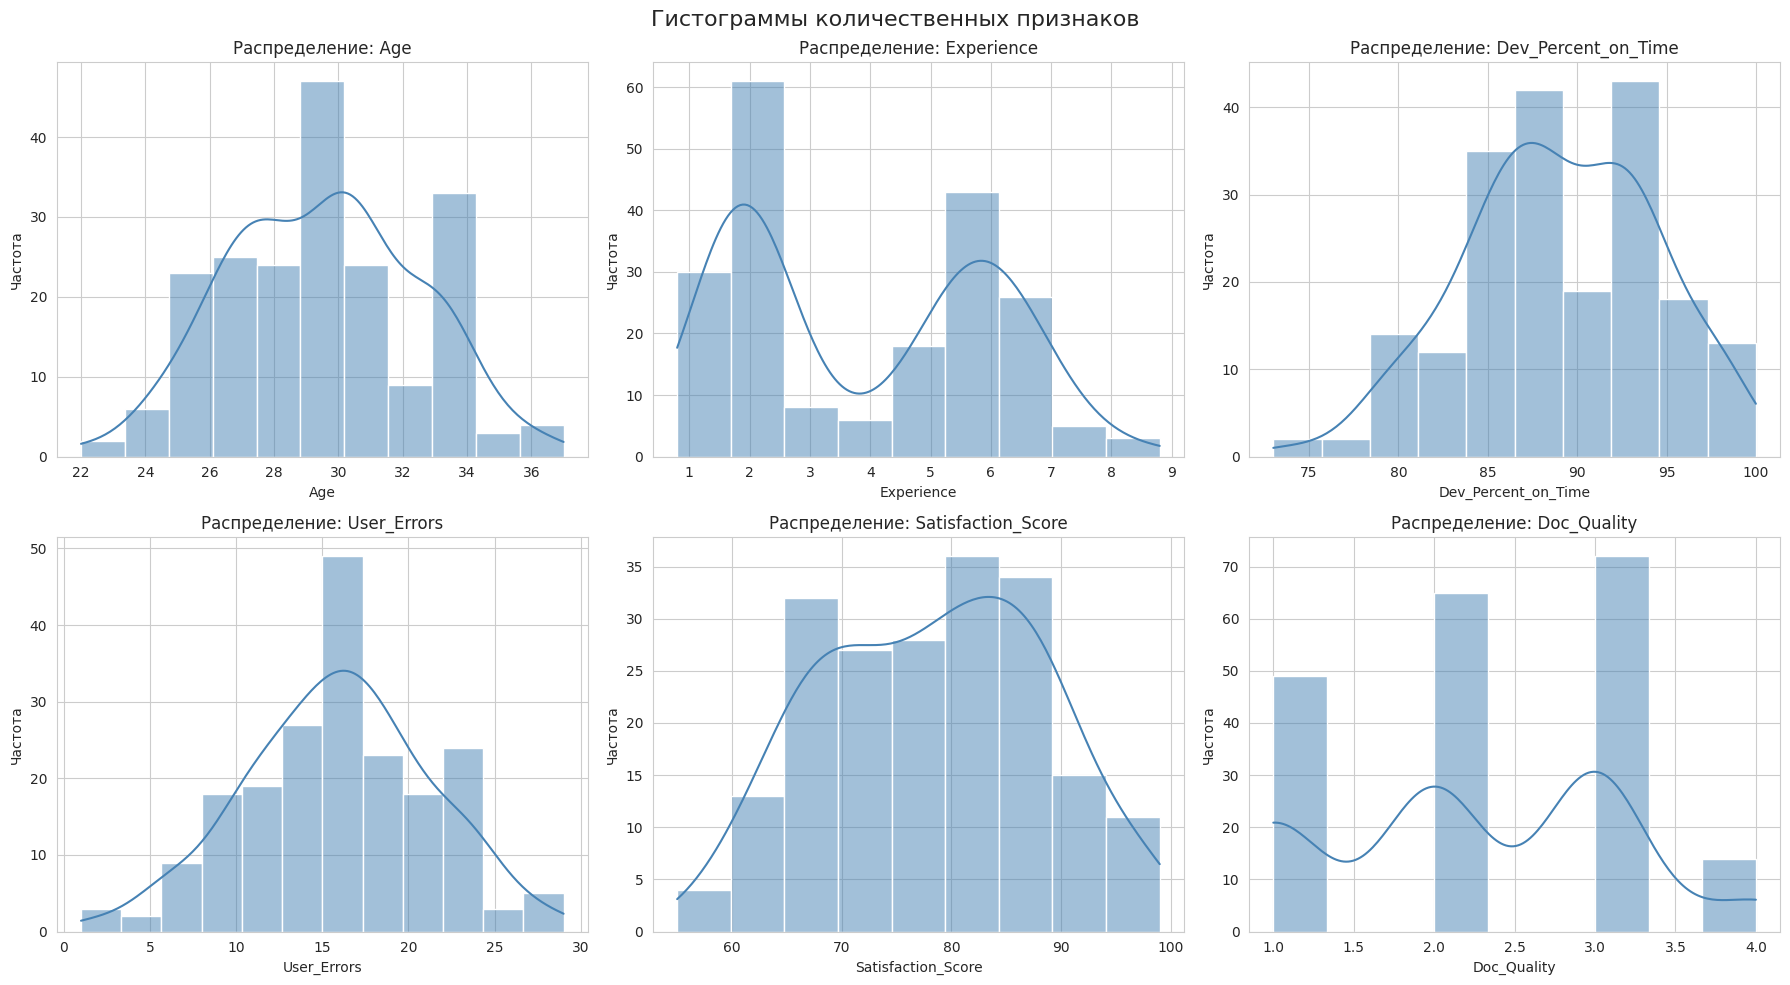

In [21]:
# 6. ГИСТОГРАММЫ ВСЕХ КОЛИЧЕСТВЕННЫХ ПРИЗНАКОВ

fig_hist, axes_hist = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

fig_hist.suptitle(
    'Гистограммы количественных признаков',
    fontsize=16
)

axes_hist = axes_hist.flatten()

for i, col in enumerate(quant_cols):

    sns.histplot(
        df[col],
        kde=True,
        ax=axes_hist[i],
        color='steelblue'
    )

    axes_hist[i].set_title(f'Распределение: {col}')
    axes_hist[i].set_xlabel(col)
    axes_hist[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

(пункт 6 и 10) Для визуального исследования взаимосвязей между признаками был построен матричный график pairplot. На диагонали представлены распределения отдельных признаков, а вне диагонали — диаграммы рассеяния для всех пар переменных. По графику можно сделать следующие наблюдения:

1. Между признаками Age и Experience наблюдается выраженная положительная зависимость: с увеличением возраста в целом возрастает и стаж.
2. Признак Dev_Percent_on_Time имеет заметную положительную связь с Satisfaction_Score: при увеличении доли задач, выполненных в срок, уровень удовлетворённости в среднем повышается.
3. Между User_Errors и Satisfaction_Score прослеживается выраженная отрицательная зависимость: увеличение количества пользовательских ошибок сопровождается снижением оценки удовлетворённости.
4. Между Dev_Percent_on_Time и User_Errors также наблюдается отрицательная связь: при более высокой доле своевременно выполненных задач количество ошибок в среднем уменьшается.
5. Для Age и Satisfaction_Score прослеживается умеренная положительная тенденция, однако разброс значений достаточно велик.
6. Связь Age с User_Errors выражена значительно слабее.
Признак Experience демонстрирует положительную связь с Age, а его взаимосвязи с Dev_Percent_on_Time и Satisfaction_Score имеют более сложную структуру: на графике заметно разделение наблюдений на группы, поэтому линейная зависимость выражена не для всех значений одинаково.
7. Признак Doc_Quality принимает ограниченное число дискретных значений от 1 до 4, поэтому на диаграммах рассеяния наблюдаются отдельные вертикальные и горизонтальные полосы. Явной линейной зависимости Doc_Quality с остальными количественными признаками по графику не прослеживается.

В целом матричный график подтверждает наличие наиболее заметных связей между Age и Experience, между Dev_Percent_on_Time и Satisfaction_Score, а также обратной зависимости между User_Errors и Satisfaction_Score. Для некоторых пар признаков наблюдается значительный разброс и кластеризация данных, поэтому окончательные выводы о силе и направлении взаимосвязей следует делать совместно с рассчитанными коэффициентами корреляции Пирсона, Спирмена и Кендалла.

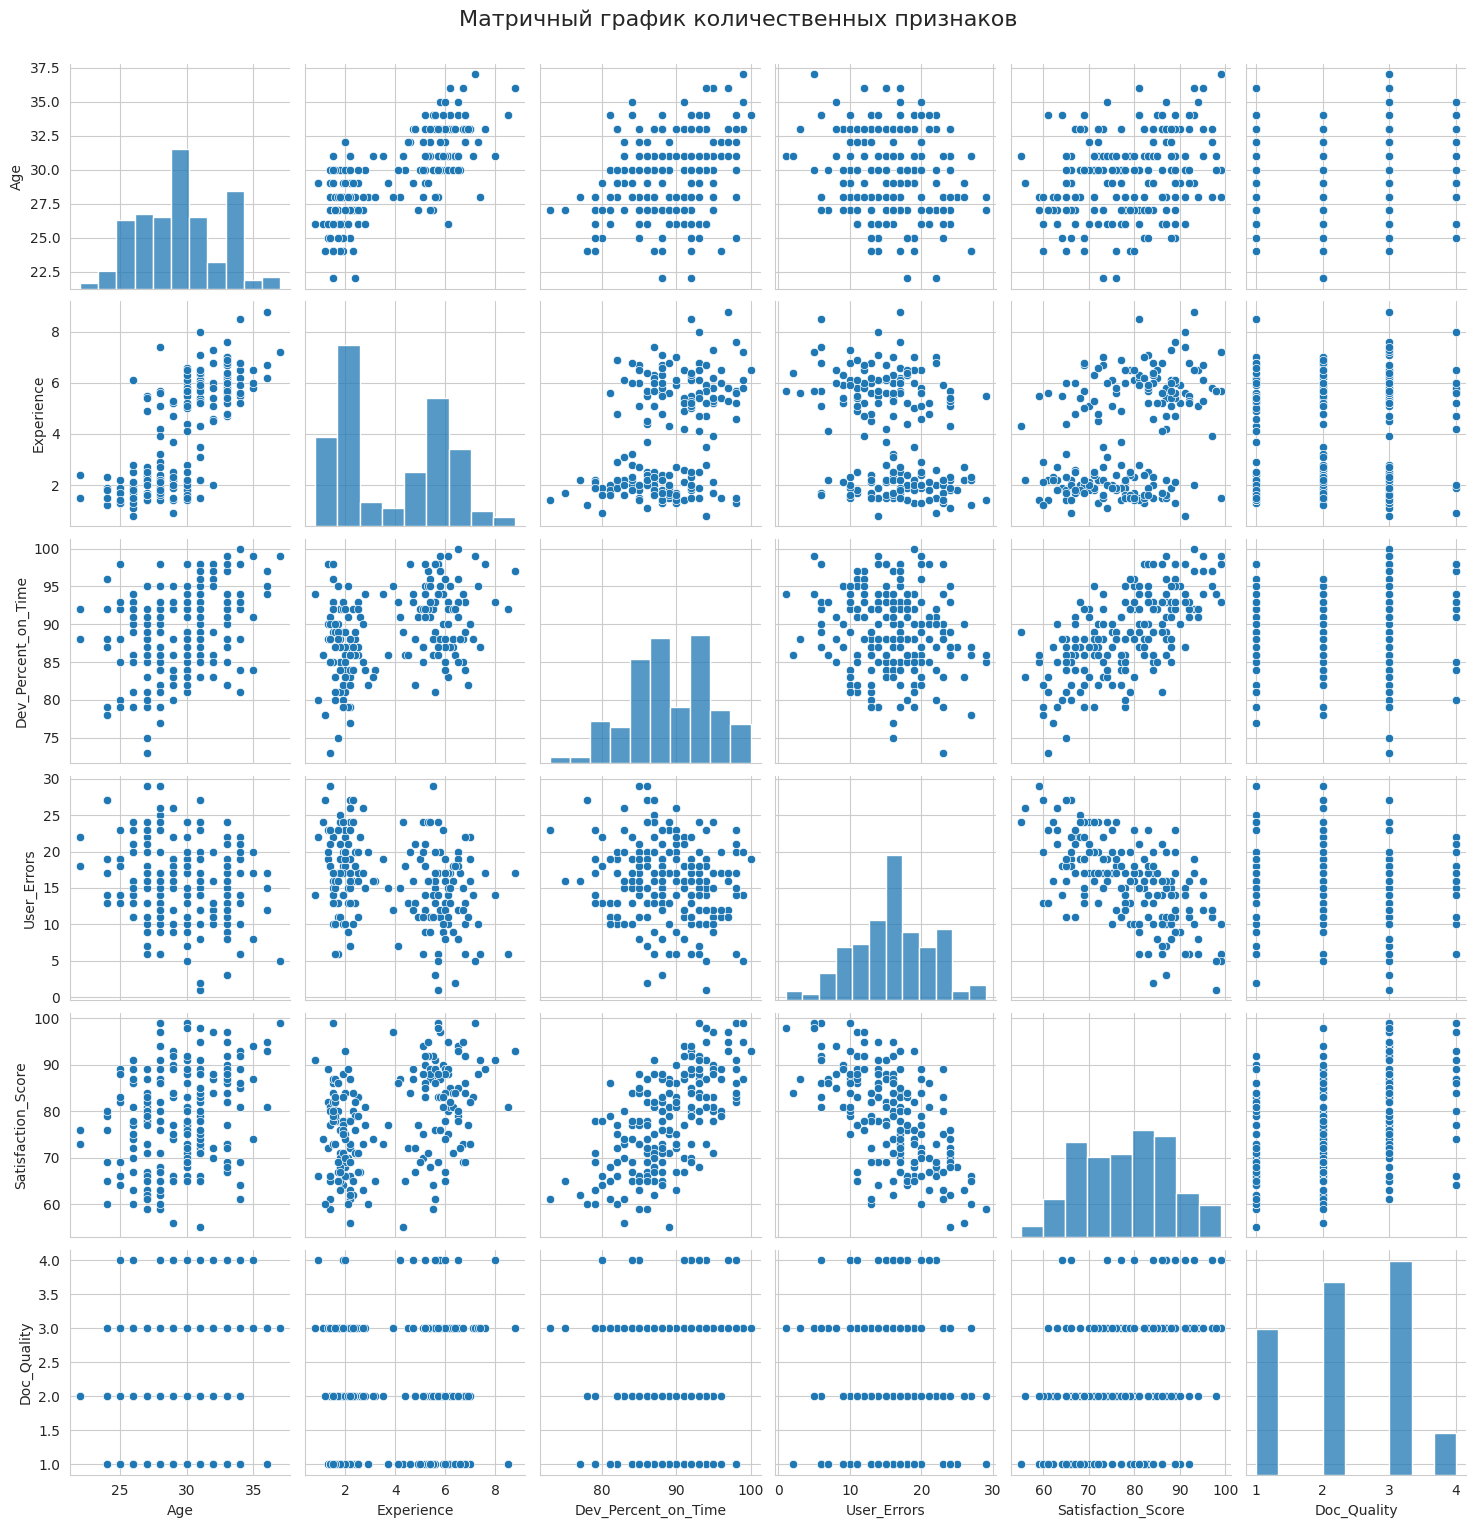

In [22]:
# ============================================================
# 7. МАТРИЧНЫЙ ГРАФИК ПО ВСЕМ КОЛИЧЕСТВЕННЫМ ПРИЗНАКАМ
# ============================================================

sns.pairplot(
    df[quant_cols],
    diag_kind='hist',
    corner=False
)

plt.suptitle(
    'Матричный график количественных признаков',
    y=1.02,
    fontsize=16
)

plt.show()

#7.1

In [23]:
def agreement_criteria(df:pd.DataFrame, feature:str):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy import stats

    # ==========================================
    # 1. Выбор признака
    # ==========================================

    x = df[feature].dropna().astype(float).to_numpy()

    n = len(x)
    mean = np.mean(x)
    std = np.std(x, ddof=1)

    alpha = 0.05


    # ==========================================
    # 2. Шапиро–Уилк
    # ==========================================

    shapiro_stat, shapiro_p = stats.shapiro(x)


    # ==========================================
    # 3. χ² Пирсона
    # ==========================================

    k = min(int(np.sqrt(n)), n // 5)
    k = max(k, 4)

    probabilities = np.linspace(0, 1, k + 1)

    edges = stats.norm.ppf(
        probabilities,
        loc=mean,
        scale=std
    )

    observed, _ = np.histogram(
        x,
        bins=edges
    )

    expected = np.full(
        k,
        n / k
    )

    chi2_stat = np.sum(
        (observed - expected)**2 /
        expected
    )

    df_chi = k - 1 - 2

    chi2_p = stats.chi2.sf(
        chi2_stat,
        df=df_chi
    )


    # ==========================================
    # 4. Крамер–Мизес
    # ==========================================

    cvm = stats.cramervonmises(
        x,
        "norm",
        args=(mean, std)
    )


    # ==========================================
    # 5. Результаты
    # ==========================================

    results = pd.DataFrame({

        "Критерий": [
            "χ² Пирсона",
            "Шапиро–Уилка",
            "Крамера–Мизеса"
        ],

        "Статистика": [
            chi2_stat,
            shapiro_stat,
            cvm.statistic
        ],

        "p-value": [
            chi2_p,
            shapiro_p,
            cvm.pvalue
        ]

    })

    results["Вывод"] = np.where(
        results["p-value"] > alpha,
        "H0 не отвергается",
        "H0 отвергается"
    )

    print("Признак:", feature)
    print("n =", n)
    print("Среднее =", round(mean, 3))
    print("Стандартное отклонение =", round(std, 3))

    display(results)


    # ==========================================
    # 6. Гистограмма + НЗР
    # ==========================================

    plt.figure(figsize=(10, 6))

    plt.hist(
        x,
        bins="auto",
        density=True,
        alpha=0.6,
        edgecolor="black",
        label="Наблюдаемые данные"
    )

    x_axis = np.linspace(
        x.min(),
        x.max(),
        500
    )

    plt.plot(
        x_axis,
        stats.norm.pdf(
            x_axis,
            mean,
            std
        ),
        linewidth=2,
        label="НЗР"
    )

    plt.xlabel(feature)
    plt.ylabel("Плотность")
    plt.title(
        f"Гистограмма распределения {feature} "
        "с наложением НЗР"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

Признак: Age
n = 200
Среднее = 29.51
Стандартное отклонение = 2.948


,Критерий,Статистика,p-value,Вывод
0,χ² Пирсона,110.940000,1.188809e-18,H0 отвергается
1,Шапиро–Уилка,0.981735,1.054223e-02,H0 отвергается
2,Крамера–Мизеса,0.274338,1.599454e-01,H0 не отвергается


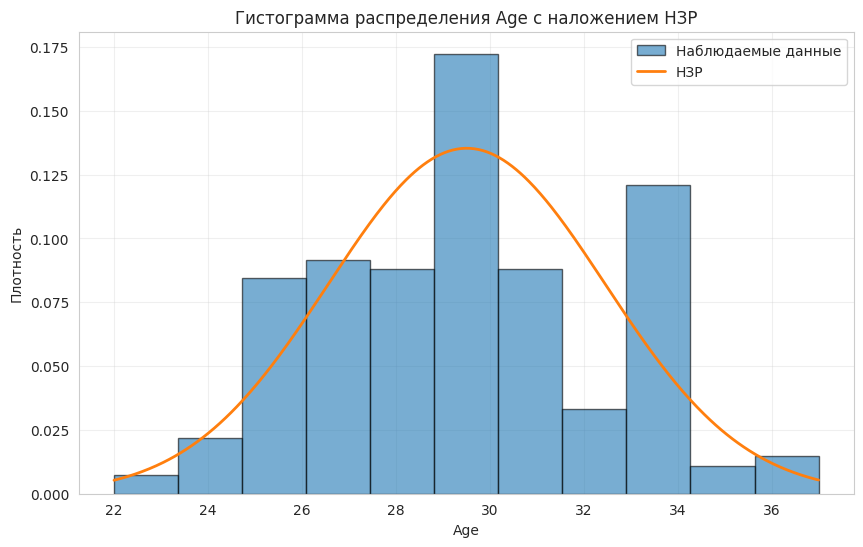

In [24]:
agreement_criteria(df, 'Age')

Анализ гипотезы о нормальном распределении признака 'Age' (n=200):

На основе результатов трех критериев согласия и визуального анализа можно сделать вывод, что нулевая гипотеза о нормальном законе распределения данных ОТВЕРГАЕТСЯ.

Обоснование:
1. Критерий χ² Пирсона показал статистически значимое расхождение между наблюдаемыми и теоретическими частотами (p-value ≈ 1.19e-18), что является самым сильным доказательством ненормальности.
2. Тест Шапиро–Уилка также отвергает H0 (p-value = 0.0105 < 0.05), подтверждая наличие систематических отклонений от нормального закона.
3. Критерий Крамера–Мизеса не отверг H0 (p-value = 0.1599), однако его результат противоречит двум другим более чувствительным тестам и визуальному представлению данных.

Графический анализ гистограммы выявляет явную бимодальность распределения (два выраженных пика в областях ~29 и ~34 года). Теоретическая кривая нормального распределения не описывает реальную структуру данных, проходя через «провал» между модами.Данные по возрасту имеют сложную структуру, вероятно, обусловленную наличием двух различных подгрупп в выборке (например, разные категории сотрудников или отделы).

#7.2

In [25]:
from scipy import stats

# Посмотрим значения групп
print(df["Group"].unique())

# Столбцы, которые нельзя считать количественными
exclude_cols = [
    "Group",
    "Gender",
    "Satisfaction_Level",
    "Doc_Quality"
]

# Оставляем только действительно количественные признаки
quant_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in exclude_cols
]

print("Количественные признаки:")
print(quant_cols)

# Первая и вторая группы
group1 = df[df["Group"] == 1][quant_cols]
group2 = df[df["Group"] == 2][quant_cols]

print("Размер первой группы:", group1.shape)
print("Размер второй группы:", group2.shape)

[1 2]
Количественные признаки:
['Age', 'Experience', 'Dev_Percent_on_Time', 'User_Errors', 'Satisfaction_Score']
Размер первой группы: (100, 5)
Размер второй группы: (100, 5)


In [26]:
# ============================================
# ГРУППА 1
# ============================================

pearson_g1 = group1.corr(method="pearson")
spearman_g1 = group1.corr(method="spearman")
kendall_g1 = group1.corr(method="kendall")
# ============================================
# ГРУППА 2
# ============================================

pearson_g2 = group2.corr(method="pearson")
spearman_g2 = group2.corr(method="spearman")
kendall_g2 = group2.corr(method="kendall")




print("======================================================")
print("МЕТОД Пирсон")
print("======================================================")
print("ГРУППА 1 — Пирсон")
display(pearson_g1.round(3))
print("ГРУППА 2 — Пирсон")
display(pearson_g2.round(3))


print("======================================================")
print("МЕТОД Спирмана")
print("======================================================")
print("ГРУППА 1 — Спирмен")
display(spearman_g1.round(3))
print("ГРУППА 2 — Спирмен")
display(spearman_g2.round(3))



print("======================================================")
print("МЕТОД Кендела")
print("======================================================")
print("ГРУППА 1 — Кендалл")
display(kendall_g1.round(3))
print("ГРУППА 2 — Кендалл")
display(kendall_g2.round(3))

МЕТОД Пирсон
ГРУППА 1 — Пирсон


,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000,0.241,-0.054,0.001,-0.043
Experience,0.241,1.000,-0.066,-0.017,-0.214
Dev_Percent_on_Time,-0.054,-0.066,1.000,-0.072,0.586
User_Errors,0.001,-0.017,-0.072,1.000,-0.581
Satisfaction_Score,-0.043,-0.214,0.586,-0.581,1.000


ГРУППА 2 — Пирсон


,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000,0.415,0.035,0.034,0.007
Experience,0.415,1.000,0.049,-0.142,0.143
Dev_Percent_on_Time,0.035,0.049,1.000,-0.035,0.612
User_Errors,0.034,-0.142,-0.035,1.000,-0.572
Satisfaction_Score,0.007,0.143,0.612,-0.572,1.000


МЕТОД Спирмана
ГРУППА 1 — Спирмен


...

,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000,0.411,0.018,0.072,-0.019
Experience,0.411,1.000,-0.011,-0.130,0.070
Dev_Percent_on_Time,0.018,-0.011,1.000,-0.029,0.604
User_Errors,0.072,-0.130,-0.029,1.000,-0.527
Satisfaction_Score,-0.019,0.070,0.604,-0.527,1.000


МЕТОД Кендела
ГРУППА 1 — Кендалл


,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000,0.176,-0.059,0.020,-0.043
Experience,0.176,1.000,-0.090,-0.010,-0.155
Dev_Percent_on_Time,-0.059,-0.090,1.000,-0.038,0.428
User_Errors,0.020,-0.010,-0.038,1.000,-0.412
Satisfaction_Score,-0.043,-0.155,0.428,-0.412,1.000


ГРУППА 2 — Кендалл


,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000,0.307,0.016,0.053,-0.012
Experience,0.307,1.000,-0.006,-0.088,0.043
Dev_Percent_on_Time,0.016,-0.006,1.000,-0.020,0.437
User_Errors,0.053,-0.088,-0.020,1.000,-0.383
Satisfaction_Score,-0.012,0.043,0.437,-0.383,1.000


Корреляционный анализ на основе коэффициентов Пирсона, Спирмена и Кендалла показал, что структура взаимосвязей в обеих группах в целом сходна. Наиболее выраженная положительная связь наблюдается между долей задач, выполненных в срок (Dev_Percent_on_Time), и уровнем удовлетворённости (Satisfaction_Score). В первой группе коэффициент Пирсона составляет \(r=0.586\), во второй — \(r=0.612\). Это свидетельствует о том, что более высокому уровню своевременного выполнения задач соответствует более высокий уровень удовлетворённости.

Наиболее выраженная отрицательная зависимость установлена между количеством пользовательских ошибок (User_Errors) и удовлетворённостью: \(r=-0.581\) для первой группы и \(r=-0.572\) для второй. Следовательно, увеличение числа ошибок связано со снижением удовлетворённости.

Между возрастом (Age) и стажем (Experience) существует положительная взаимосвязь, причём во второй группе она выражена сильнее: коэффициент Пирсона увеличивается с \(0.241\) до \(0.415\). Для большинства остальных пар признаков коэффициенты близки к нулю, что свидетельствует об отсутствии выраженной линейной или монотонной зависимости.

Значения коэффициентов Пирсона и Спирмена для основных взаимосвязей близки друг к другу, а коэффициент Кендалла показывает те же направления связи, хотя имеет меньшие по модулю значения вследствие особенностей его расчёта. Совпадение результатов трёх методов подтверждает устойчивость выявленных зависимостей.

#7.4

In [27]:
var_x = "Age"
var_y = "Experience"

# Удаляем строки с пропущенными значениями
pair = group1[[var_x, var_y]]
x = pair[var_x]
y = pair[var_y]

r_check, p_check = stats.pearsonr(x, y)

print("r Пирсона =",r_check)
print("p-value =", p_check)

alpha = 0.05

if p_check < alpha:
    print("H0 отвергается.")
    print("Корреляция статистически значима.")
else:
    print("Нет оснований отвергать H0.")
    print("Статистическая значимость корреляции не установлена.")

r Пирсона = 0.2413475590367436
p-value = 0.015562972357679337
H0 отвергается.
Корреляция статистически значима.


Между исследуемыми признаками обнаружена слабая положительная линейная связь, коэффициент корреляции Пирсона составляет \(r=0.241\). Это означает, что при увеличении одного признака наблюдается тенденция к увеличению второго, однако выраженность данной зависимости невелика. Полученное значение \(p=0.0156\) меньше принятого уровня значимости \(\alpha=0.05\), поэтому нулевая гипотеза об отсутствии линейной корреляционной связи отвергается. Следовательно, выявленная положительная связь является статистически значимой.

In [28]:
corr_matrix1 = group1.corr(method='pearson')
display(corr_matrix1)

corr_matrix2 = group2.corr(method='pearson')
display(corr_matrix2)

,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000000,0.241348,-0.054315,0.000618,-0.043291
Experience,0.241348,1.000000,-0.065902,-0.016767,-0.214336
Dev_Percent_on_Time,-0.054315,-0.065902,1.000000,-0.071588,0.585849
User_Errors,0.000618,-0.016767,-0.071588,1.000000,-0.581407
Satisfaction_Score,-0.043291,-0.214336,0.585849,-0.581407,1.000000


,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score
Age,1.000000,0.415407,0.034757,0.033595,0.007392
Experience,0.415407,1.000000,0.048578,-0.142331,0.142675
Dev_Percent_on_Time,0.034757,0.048578,1.000000,-0.035006,0.611821
User_Errors,0.033595,-0.142331,-0.035006,1.000000,-0.572399
Satisfaction_Score,0.007392,0.142675,0.611821,-0.572399,1.000000


Для оценки взаимосвязей между количественными признаками были рассчитаны частные коэффициенты корреляции Пирсона отдельно для первой и второй групп. При расчёте связи между каждой парой признаков влияние остальных количественных переменных статистически исключалось. В обеих группах наиболее выраженная положительная частная связь обнаружена между Dev_Percent_on_Time и Satisfaction_Score: \(r_p\approx0.681\) для первой группы и \(r_p\approx0.722\) для второй группы. Это свидетельствует о том, что более высокая доля задач, выполненных в срок, связана с более высокой удовлетворённостью даже после учёта возраста, стажа и количества пользовательских ошибок.

Наиболее выраженная отрицательная частная связь наблюдается между User_Errors и Satisfaction_Score: \(r_p\approx-0.689\) в первой группе и \(r_p\approx-0.688\) во второй. Следовательно, увеличение количества пользовательских ошибок связано со снижением удовлетворённости, причём данная зависимость сохраняется после статистического исключения влияния остальных количественных признаков.

Между Age и Experience сохраняется положительная связь: \(r_p\approx0.244\) в первой группе и \(r_p\approx0.424\) во второй. Во второй группе эта зависимость выражена сильнее. Для большинства связей возраста с остальными показателями частные коэффициенты близки к нулю, что свидетельствует об отсутствии выраженной самостоятельной линейной взаимосвязи после учёта остальных факторов.

#7.5

Для оценки линейной взаимосвязи между числовыми признаками была построена матрица корреляции Пирсона. Визуализация в виде тепловой карты позволяет быстро выявить сильно коррелирующие признаки: тёплые тона (ближе к +1) указывают на прямую связь, холодные (ближе к –1) — на обратную, а нейтральный цвет (около 0) — на отсутствие линейной зависимости.

,Group,Gender,Age,Experience,Dev_Percent_on_Time,User_Errors,Satisfaction_Score,Satisfaction_Level,Doc_Quality
Group,1.000000,-0.100000,0.693625,0.938427,0.421975,-0.306999,0.412887,0.294884,0.071782
Gender,-0.100000,1.000000,-0.112204,-0.097406,-0.066727,-0.023187,0.037713,0.058977,0.248475
Age,0.693625,-0.112204,1.000000,0.736928,0.285525,-0.200337,0.276088,0.180475,0.078833
Experience,0.938427,-0.097406,0.736928,1.000000,0.397671,-0.320321,0.396001,0.275676,0.071203
Dev_Percent_on_Time,0.421975,-0.066727,0.285525,0.397671,1.000000,-0.175613,0.665224,0.560505,0.057876
User_Errors,-0.306999,-0.023187,-0.200337,-0.320321,-0.175613,1.000000,-0.626413,-0.553157,-0.052375
Satisfaction_Score,0.412887,0.037713,0.276088,0.396001,0.665224,-0.626413,1.000000,0.858269,0.398054
Satisfaction_Level,0.294884,0.058977,0.180475,0.275676,0.560505,-0.553157,0.858269,1.000000,0.313438
Doc_Quality,0.071782,0.248475,0.078833,0.071203,0.057876,-0.052375,0.398054,0.313438,1.000000


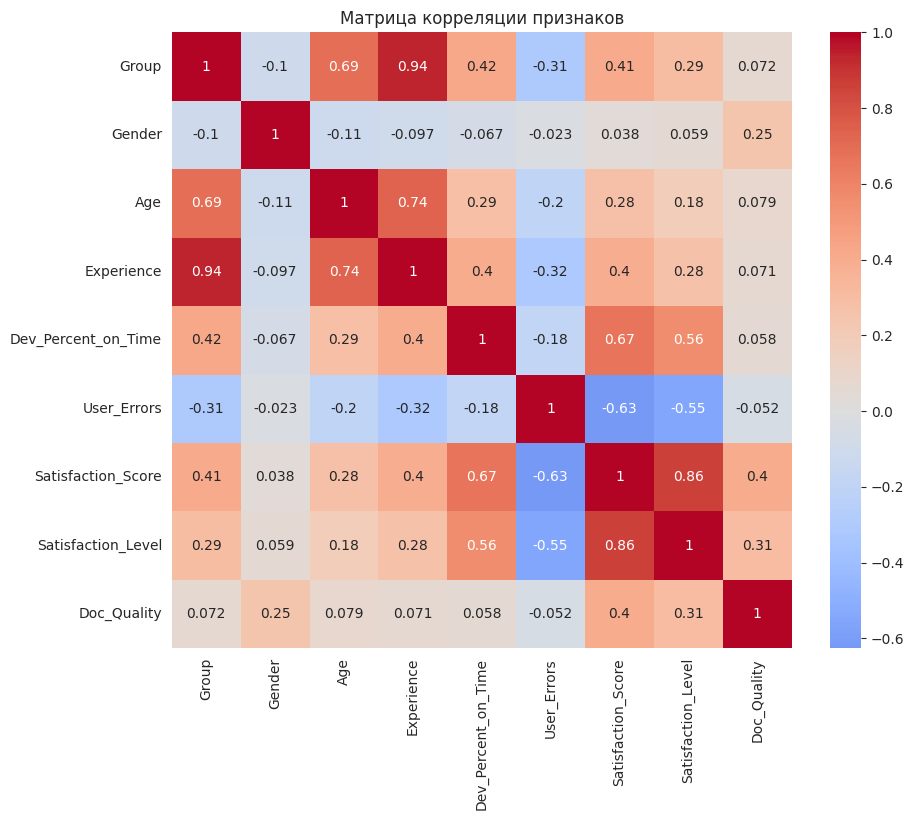

In [29]:
corr_matrix = df.corr(method='pearson')
display(corr_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Матрица корреляции признаков")
plt.show()

Анализ матрицы корреляций Пирсона позволяет сделать следующие выводы о взаимосвязях между количественными показателями эффективности и удовлетворенности разработчиков:

1. Сильная прямая связь между опытом и своевременностью (r ≈ 0.40):
Наблюдается умеренная положительная корреляция между стажем работы (Experience) и процентом задач, выполненных в срок (Dev_Percent_on_Time). Это указывает на то, что более опытные специалисты склонны лучше оценивать свои силы и соблюдать дедлайны, либо обладают навыками, позволяющими работать эффективнее.

2. Ключевой драйвер удовлетворенности — качество коммуникации и процессов (r ≈ 0.67):
Самая сильная связь в матрице обнаружена между Satisfaction_Score и Dev_Percent_on_Time. Высокий процент выполнения задач в срок является мощным предиктором высокой удовлетворенности работой. Это подтверждает гипотезу о том, что отсутствие авралов и предсказуемость рабочего процесса критически важны для комфорта сотрудника.

3. Влияние ошибок на удовлетворенность (r ≈ -0.63):
Выявлена сильная обратная связь между количеством ошибок пользователя (User_Errors) и общей удовлетворенностью (Satisfaction_Score). Чем больше багов или проблем возникает у пользователей из-за работы разработчика, тем ниже его самооценка удовлетворенности (вероятно, из-за давления со стороны поддержки, чувства вины или сложности исправлений).

4. Согласованность метрик удовлетворенности (r ≈ 0.86):
Между Satisfaction_Score (числовая оценка) и Satisfaction_Level (уровень) наблюдается очень высокая корреляция. Метрики дублируют друг друга и измеряют один и тот же латентный признак.

5. Слабая связь возраста и качества документации (r ≈ 0.08):
Корреляция между возрастом (Age) и качеством документации (Doc_Quality) практически отсутствует. Это важный вывод для HR и менеджмента: возраст сотрудника не гарантирует ни лучшего, ни худшего оформления документации. Качество docs зависит от других факторов (дисциплина, стандарты компании), а не от зрелости.

Общий итог:
Эффективность работы (соблюдение сроков) и качество кода (отсутствие ошибок) являются фундаментальными факторами удовлетворенности разработчиков. Для повышения Satisfaction_Score менеджменту следует фокусироваться не на возрасте сотрудников, а на процессах планирования (чтобы повысить On_Time %) и улучшения тестирования/код-ревью (чтобы снизить User_Errors).

#7.6

In [30]:
quant_cols = [
    "Age",
    "Experience",
    "Dev_Percent_on_Time",
    "User_Errors",
    "Satisfaction_Score"
]

factor = "Group"

anova_results = []

for col in quant_cols:

    # Формируем группы
    groups = [
        group[col].dropna().values
        for name, group in df.groupby(factor)
    ]

    # -------------------------
    # ANOVA
    # -------------------------
    F, p_anova = stats.f_oneway(*groups)

    # -------------------------
    # Краскел–Уоллис
    # -------------------------
    H, p_kw = stats.kruskal(*groups)

    anova_results.append({
        "Признак": col,
        "F_ANOVA": F,
        "p_ANOVA": p_anova,
        "H_Kruskal": H,
        "p_Kruskal": p_kw
    })

results8 = pd.DataFrame(anova_results)



alpha = 0.05

results8["ANOVA вывод"] = np.where(
    results8["p_ANOVA"] < alpha,
    "Различия статистически значимы",
    "Статистически значимых различий нет"
)

results8["Краскел вывод"] = np.where(
    results8["p_Kruskal"] < alpha,
    "Различия статистически значимы",
    "Статистически значимых различий нет"
)


def eta_squared(data, factor, value):

    temp = data[[factor, value]].dropna()

    grand_mean = temp[value].mean()

    ss_between = sum(
        len(group) * (group[value].mean() - grand_mean)**2
        for _, group in temp.groupby(factor)
    )

    ss_total = sum(
        (temp[value] - grand_mean)**2
    )

    return ss_between / ss_total

results8["eta_squared"] = [
    eta_squared(df, factor, col)
    for col in quant_cols
]

display(results8.round(5))

,Признак,F_ANOVA,p_ANOVA,H_Kruskal,p_Kruskal,ANOVA вывод,Краскел вывод,eta_squared
0,Age,183.58773,0.00000,101.35376,0.00000,Различия статистически значимы,Различия статистически значимы,0.48112
1,Experience,1460.92482,0.00000,149.39682,0.00000,Различия статистически значимы,Различия статистически значимы,0.88065
2,Dev_Percent_on_Time,42.89429,0.00000,33.55549,0.00000,Различия статистически значимы,Различия статистически значимы,0.17806
3,User_Errors,20.60297,0.00001,18.12138,0.00002,Различия статистически значимы,Различия статистически значимы,0.09425
4,Satisfaction_Score,40.69093,0.00000,35.72421,0.00000,Различия статистически значимы,Различия статистически значимы,0.17048


Для оценки взаимосвязи качественного признака Group с количественными показателями был проведён однофакторный дисперсионный анализ ANOVA и непараметрический критерий Краскела–Уоллиса. При уровне значимости \(alpha=0.05) для всех рассмотренных количественных признаков получены значения \(p<0.05\). Следовательно, нулевая гипотеза об отсутствии различий между группами отвергается для признаков Age, Experience, Dev_Percent_on_Time, User_Errors и Satisfaction_Score.


Наиболее выраженная связь с принадлежностью к группе обнаружена для стажа Experience (\(eta^2=0.881)), что соответствует очень сильному эффекту: около 88.1% вариации стажа связано с групповым фактором. Для возраста Age также обнаружен сильный эффект (\(eta^2=0.481)). Сильная взаимосвязь установлена для доли своевременно выполненных задач Dev_Percent_on_Time (\(eta^2=0.178)) и уровня удовлетворённости Satisfaction_Score (\(eta^2=0.170)). Для количества пользовательских ошибок User_Errors эффект имеет среднюю величину (\(eta^2=0.094)).


Результаты критерия Краскела–Уоллиса полностью согласуются с результатами ANOVA: для всех пяти признаков получены статистически значимые различия между группами.

#8

In [31]:
from itertools import combinations

cat_cols = [
    "Group",
    "Gender",
    "Satisfaction_Level",
    "Doc_Quality"
]

chi_results = []

for x, y in combinations(cat_cols, 2):

    table = pd.crosstab(df[x], df[y])

    chi2, p, dof, expected = stats.chi2_contingency(table)

    chi_results.append({
        "Признак 1": x,
        "Признак 2": y,
        "chi2": chi2,
        "df": dof,
        "p_value": p
    })

chi_df = pd.DataFrame(chi_results)



chi_df["Вывод"] = np.where(
    chi_df["p_value"] < 0.05,
    "Статистически значимая связь",
    "Статистически значимая связь не обнаружена"
)

display(chi_df.round(5))

,Признак 1,Признак 2,chi2,df,p_value,Вывод
0,Group,Gender,1.62000,1,0.20309,Статистически значимая связь не обнаружена
1,Group,Satisfaction_Level,18.29852,2,0.00011,Статистически значимая связь
2,Group,Doc_Quality,3.89355,3,0.27319,Статистически значимая связь не обнаружена
3,Gender,Satisfaction_Level,1.07327,2,0.58471,Статистически значимая связь не обнаружена
4,Gender,Doc_Quality,20.03642,3,0.00017,Статистически значимая связь
5,Satisfaction_Level,Doc_Quality,28.98667,6,0.00006,Статистически значимая связь


Наличие статистически значимой взаимосвязи между принадлежностью к группе и уровнем удовлетворённости (\(p=0.00011\)), между полом и качеством документации (\(p=0.00017\)), а также между уровнем удовлетворённости и качеством документации (\(p=0.00006\)). Для остальных исследованных пар статистически значимая зависимость при \(\alpha=0.05\) не установлена. Таким образом, не все качественные признаки являются независимыми: уровень удовлетворённости связан с принадлежностью к группе и качеством документации, а качество документации также связано с полом. При этом статистическая значимость связи сама по себе не определяет её силу и не свидетельствует о причинно-следственной зависимости.

#Вывод

В ходе лабораторной работы был проведён первичный разведочный и статистический анализ набора данных, содержащего 200 наблюдений о показателях работы специалистов и удовлетворённости заказчиков. Были определены типы признаков, рассчитаны основные описательные статистики, исследованы распределения и выбросы, а также выполнен корреляционный, дисперсионный анализ и анализ таблиц сопряжённости. Пропущенные значения в исходных данных отсутствуют. Анализ межквартильного размаха показал, что выборка практически не содержит выраженных выбросов: только для количества ошибок обнаружено одно наблюдение за установленными границами, что составляет 0,5 % выборки.

Анализ распределений показал, что количественные признаки имеют различную структуру. Для признака Age гипотеза о нормальном распределении была проверена критериями χ² Пирсона, Шапиро–Уилка и Крамера–Мизеса. Критерии χ² и Шапиро–Уилка дали основания отвергнуть гипотезу о нормальности при уровне значимости \(\alpha=0.05\), тогда как критерий Крамера–Мизеса её не отверг. С учётом результатов большинства критериев и графического анализа распределение возраста нельзя считать нормально распределённым. Это показывает необходимость применения наряду с параметрическими также непараметрических статистических методов.

Корреляционный анализ по Пирсону, Спирмену и Кендаллу показал сходную структуру взаимосвязей в обеих исследуемых группах. Наиболее выраженная положительная зависимость обнаружена между долей разработок, выполненных в срок, и оценкой удовлетворённости заказчиков: коэффициент Пирсона составил \(r=0.586\) для первой и \(r=0.612\) для второй группы. Наиболее выраженная отрицательная зависимость выявлена между количеством ошибок, обнаруженных пользователем, и удовлетворённостью: \(r=-0.581\) и \(r=-0.572\) соответственно. Следовательно, своевременное выполнение работ связано с более высокой удовлетворённостью заказчика, тогда как увеличение числа обнаруженных ошибок связано с её снижением. Между возрастом и стажем также существует положительная связь, причём во второй группе она выражена сильнее. Для выбранной пары Age–Experience в первой группе слабая положительная корреляция \(r=0.241\) оказалась статистически значимой (\(p=0.0156<0.05\)).

Анализ частных корреляций показал, что основные зависимости сохраняются даже после исключения влияния остальных количественных факторов. В частности, частная корреляция между своевременностью выполнения работ и удовлетворённостью составила приблизительно \(0.681\) в первой группе и \(0.722\) во второй, а между количеством выявленных ошибок и удовлетворённостью — около \(-0.689\) и \(-0.688\). Следовательно, эти связи нельзя объяснить только влиянием возраста, стажа или других рассмотренных количественных показателей.

Однофакторный дисперсионный анализ ANOVA и критерий Краскела–Уоллиса показали статистически значимые различия между группами по всем исследованным количественным признакам (\(p<0.05\)). Наиболее сильная связь с принадлежностью к группе выявлена для стажа: \(\eta^2=0.881\), то есть групповой фактор связан примерно с 88,1 % вариации этого показателя. Сильный эффект также обнаружен для возраста (\(\eta^2=0.481\)), доли своевременно выполненных работ (\(\eta^2=0.178\)) и оценки удовлетворённости (\(\eta^2=0.170\)). Для количества ошибок эффект оказался менее выраженным, но также существенным (\(\eta^2=0.094\)). Совпадение результатов ANOVA и непараметрического критерия Краскела–Уоллиса подтверждает устойчивость обнаруженных межгрупповых различий.

Анализ качественных признаков с использованием таблиц сопряжённости и критерия χ² показал статистически значимую зависимость между группой и уровнем удовлетворённости (\(p=0.00011\)), между полом и качеством документации (\(p=0.00017\)), а также между уровнем удовлетворённости и качеством документации (\(p=0.00006\)). В то же время статистически значимой зависимости между группой и полом, группой и качеством документации, а также между полом и уровнем удовлетворённости не обнаружено.

Графический анализ — гистограммы, диаграммы рассеяния, boxplot, категориальные диаграммы, тепловая карта и матричный график — в целом подтвердил результаты статистических расчётов. Наиболее отчётливо визуально проявляются положительная связь своевременности выполнения работ с удовлетворённостью и отрицательная связь количества выявленных ошибок с удовлетворённостью.

Таким образом, проведённый анализ показал, что показатели качества и своевременности выполнения работ имеют существенную статистическую связь с удовлетворённостью заказчиков. В особенности более высокая доля работ, выполненных в срок, соответствует более высокой удовлетворённости, а увеличение числа обнаруженных ошибок — более низкой. Принадлежность к группе также существенно связана с большинством количественных характеристик. Применение параметрических и непараметрических методов позволило получить согласованные результаты и комплексно оценить структуру исследуемых данных. При этом обнаруженные статистические зависимости характеризуют совместное изменение признаков и сами по себе не доказывают причинно-следственные отношения.